In [1]:
!find /kaggle/input -maxdepth 5 -name B.csv

/kaggle/input/notebooks/theokorir/knee-mri-diagnosis-labelling/B.csv


In [2]:
CODE = "/kaggle/input/datasets/theokorir/knee-mri-pipeline/knee_pipeline"
DATA = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
LAB  = "/kaggle/input/notebooks/theokorir/knee-mri-diagnosis-labelling"

In [3]:
!pip install -q langdetect
!python $CODE/labeler_combine.py combine --train_csv $DATA/train.csv --a $LAB/A.csv --b $LAB/B.csv --out /kaggle/working/labels_soft.csv --reliability_out /kaggle/working/reliability.csv

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 16.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
mixing weights: A=0.20 B=0.34
Labeler A coverage: 1646 of 4407 reports are in languages A does not cover -> A confidence set to 0 there. Languages: {'tr': 546, 'hr': 406, 'el': 321, 'bg': 220, 'nl': 153}
                  n_gold  n_pos  n_neg  auc_A  auc_B  auc_mean  kappa_A_vs_B_all  prev_A  prev_B
label                                                                                           
ACL                   58     24     34  0.844  0.956     0.954             0.635   0.086   0.149
MCL                   58      9     49  0.811  0.929     0.943             0.477   0.049   0.129
Medial Meniscus       58     26     32  0.704  0.924     0.885             0.452   0.184   0.411
Lateral Meniscus      58     23     35  0.778  0.822     0.862             0.477   0.123   0.165
Medial OA             58     15     43  0.610  0.881     0.878             0.290   0.124   0

In [4]:
import pandas as pd
ls = pd.read_csv("/kaggle/working/labels_soft.csv")
L = [c[2:] for c in ls.columns if c.startswith("y_")]
print(pd.DataFrame({"positive (y>=.8)": [(ls[f"y_{l}"]>=.8).sum() for l in L],
                    "uncertain (.2-.8)": [((ls[f"y_{l}"]>.2)&(ls[f"y_{l}"]<.8)).sum() for l in L],
                    "mean weight": [round(ls[f"w_{l}"].mean(),2) for l in L]}, index=L))

                  positive (y>=.8)  uncertain (.2-.8)  mean weight
ACL                            650                139         0.59
MCL                            550                 99         0.58
Medial Meniscus               1771                161         0.51
Lateral Meniscus               705                103         0.48
Medial OA                     1465                126         0.49
Lateral OA                     721                166         0.42
PF OA                         1607                147         0.38
Effusion                      2664                 58         0.21
Synovitis                     1018                  7         0.33
Baker's                       1308                 46         0.52
Contusion                      641                279         0.33
Fracture                       229                 72         0.45


In [5]:
!pip install -q pylibjpeg pylibjpeg-libjpeg pylibjpeg-openjpeg
!python $CODE/cache_data.py --split train --data_dir $DATA --out /kaggle/working/cache --D 24 --size 160 --K 1 --workers 4 --limit 20

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 49.6 MB/s eta 0:00:00
20/20 studies | 12s
failed/empty studies: 0 | saved /kaggle/working/cache/cache_index.csv


1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260.npy (3, 24, 160, 160) uint8 min/max 0 255
{'present_0': 1, 'present_1': 1, 'present_2': 1, 'site_proxy': 'Siemens Heal|MAGNETOM Aera|1.5T'}


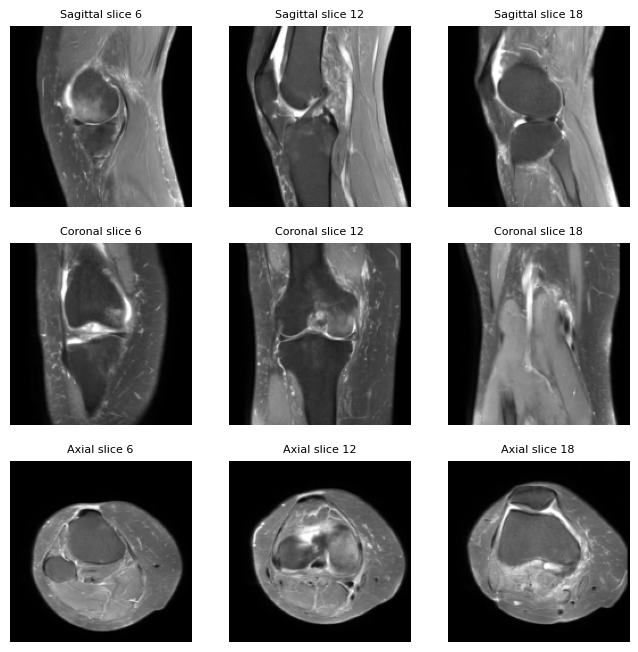

In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, glob
f = sorted(glob.glob("/kaggle/working/cache/*.npy"))[0]
x = np.load(f); print(f.split("/")[-1], x.shape, x.dtype, "min/max", x.min(), x.max())
idx = pd.read_csv("/kaggle/working/cache/cache_index.csv"); print(idx.iloc[0][["present_0","present_1","present_2","site_proxy"]].to_dict())
fig, ax = plt.subplots(3, 3, figsize=(8, 8))
for s, name in enumerate(["Sagittal", "Coronal", "Axial"]):
    for j, k in enumerate([6, 12, 18]):
        ax[s, j].imshow(x[s, k], cmap="gray"); ax[s, j].axis("off"); ax[s, j].set_title(f"{name} slice {k}", fontsize=8)
plt.show()

In [7]:
!rm -rf /kaggle/working/cache
!python $CODE/cache_data.py --split train --data_dir $DATA --out /kaggle/working/cache --D 24 --size 160 --K 1 --workers 4
!du -sh /kaggle/working/cache

50/4407 studies | 23s
100/4407 studies | 52s
150/4407 studies | 87s
200/4407 studies | 122s
250/4407 studies | 152s
300/4407 studies | 181s
350/4407 studies | 209s
400/4407 studies | 239s
450/4407 studies | 269s
500/4407 studies | 301s
550/4407 studies | 327s
600/4407 studies | 354s
650/4407 studies | 380s
700/4407 studies | 411s
750/4407 studies | 438s
800/4407 studies | 466s
850/4407 studies | 497s
900/4407 studies | 525s
950/4407 studies | 551s
1000/4407 studies | 577s
1050/4407 studies | 604s
1100/4407 studies | 631s
1150/4407 studies | 658s
1200/4407 studies | 686s
1250/4407 studies | 741s
1300/4407 studies | 771s
1350/4407 studies | 799s
1400/4407 studies | 827s
1450/4407 studies | 852s
1500/4407 studies | 882s
1550/4407 studies | 908s
1600/4407 studies | 937s
1650/4407 studies | 963s
1700/4407 studies | 989s
1750/4407 studies | 1012s
1800/4407 studies | 1037s
1850/4407 studies | 1071s
1900/4407 studies | 1098s
1950/4407 studies | 1127s
2000/4407 studies | 1153s
2050/4407 studies